# Predicting Blood Donation: Blood Transfusion Service Center

**Author:** Rekha S.C. | **Tools:** Python, Pandas, Scikit-learn, Seaborn, Matplotlib

## 1. Problem Statement
Blood banks depend on regular donors, but it is hard to know which past donors will come back. Contacting everyone is costly, and a missed donation can mean a shortage.
This project asks: **can we predict whether a person will donate blood in a given month, using only their donation history?**

## 2. Objective
- Explore the donor dataset and understand its structure and class balance.
- Build a classification model that predicts whether a donor gives blood again (`1` = donated, `0` = did not donate).
- Evaluate the model honestly, including where it fails, and list how to improve it.

## 3. Dataset
- **Source:** UCI Machine Learning Repository, *Blood Transfusion Service Center* dataset (file: `datasets/transfusion.data`).
- **Size:** 748 donors, 4 input features and 1 target, with no missing values.

| Column | Meaning |
| --- | --- |
| Recency (months) | Months since the donor's last donation |
| Frequency (times) | Total number of donations |
| Monetary (c.c. blood) | Total blood donated, in c.c. |
| Time (months) | Months since the donor's first donation |
| target | `1` if the donor gave blood in March 2007, else `0` |

## 4. Approach
1. Import libraries and load the data
2. Explore the data
3. Prepare the data (rename the target, check class balance)
4. Split into training and test sets
5. Train a Logistic Regression model, with and without feature scaling
6. Evaluate with accuracy and a confusion matrix
7. Summarise results, limitations and next steps

## 5. Import Libraries

In [12]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix

## 6. Load the Dataset
Read the data file from the `datasets` folder and preview the first five rows.

In [13]:
import pandas as pd

# Load dataset directly from UCI Machine Learning Repository
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/blood-transfusion/transfusion.data"

df = pd.read_csv(url)

# Create folder
import os
os.makedirs("datasets", exist_ok=True)

# Save full dataset (748 rows)
df.to_csv("datasets/transfusion.data", index=False)

print("Full dataset created successfully with", len(df), "rows!")


Full dataset created successfully with 748 rows!


## 7. Explore the Data
`info()` shows all 5 columns are numeric (`int64`) and none has missing values, so no cleaning is needed.

In [14]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 748 entries, 0 to 747
Data columns (total 5 columns):
 #   Column                                      Non-Null Count  Dtype
---  ------                                      --------------  -----
 0   Recency (months)                            748 non-null    int64
 1   Frequency (times)                           748 non-null    int64
 2   Monetary (c.c. blood)                       748 non-null    int64
 3   Time (months)                               748 non-null    int64
 4   whether he/she donated blood in March 2007  748 non-null    int64
dtypes: int64(5)
memory usage: 29.3 KB


## 8. Data Preparation
The target column name is long, so rename it to `target` for easier use.

In [15]:
# rename the target column
df.rename(
    columns={"whether he/she donated blood in March 2007": "target"},
    inplace=True
)

# show first 2 rows to verify
df.head(2)

,Recency (months),Frequency (times),Monetary (c.c. blood),Time (months),target
0,2,50,12500,98,1
1,0,13,3250,28,1


## 9. Class Balance
Check how many donors did and did not donate.

**Insight:** about **76.2%** of donors did not donate and **23.8%** did. The data is **imbalanced**, so a model can score high accuracy simply by predicting "no donation" every time. This matters when judging the results below.

In [16]:
df["target"].value_counts(normalize=True).round(3)

target
0    0.762
1    0.238
Name: proportion, dtype: float64

## 10. Train/Test Split
- Features (`X`): the four donation-history columns. Target (`y`): `target`.
- 75% training (561 rows) and 25% testing (187 rows).
- `stratify=y` keeps the same donor / non-donor ratio in both sets, and `random_state=42` makes the result repeatable.

In [17]:
X = df.drop("target", axis=1)
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

X_train.shape, X_test.shape

((561, 4), (187, 4))

## 11. Model: Logistic Regression
Logistic Regression is a simple, interpretable baseline for yes/no prediction. Train it on the training data.

In [18]:
log_reg = LogisticRegression(max_iter=1000)

log_reg.fit(X_train, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

## 12. Evaluate: Accuracy
Predict on the unseen test set and measure accuracy.

**Result:** accuracy is about **77.0%**. This is only slightly above the 76.5% a model would get by always predicting "no donation" on this test set, so accuracy alone is not enough here.

In [19]:
y_pred = log_reg.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

accuracy

0.7700534759358288

## 13. Feature Scaling
Features are on very different scales (for example, blood volume is in thousands of c.c., recency is in months). Standardise them and retrain to see if it helps.

**Result:** accuracy stays at about **77.0%**, so scaling made no difference for this model.

In [20]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

log_reg_scaled = LogisticRegression(max_iter=1000)
log_reg_scaled.fit(X_train_scaled, y_train)

y_pred_scaled = log_reg_scaled.predict(X_test_scaled)

accuracy_scaled = accuracy_score(y_test, y_pred_scaled)

accuracy_scaled

0.7700534759358288

## 14. Confusion Matrix
A confusion matrix shows exactly where the model is right and wrong.

| | Predicted: No | Predicted: Yes |
| --- | --- | --- |
| **Actual: No** | 140 (correct) | 3 (false alarm) |
| **Actual: Yes** | 40 (missed donors) | 4 (correct) |

The model finds only **4 of 44 real donors** (recall about 9%), but is correct on 4 of the 7 donors it predicts (precision about 57%).

In [21]:
cm = confusion_matrix(y_test, y_pred_scaled)
cm

array([[140,   3],
       [ 40,   4]], dtype=int64)

**Confusion matrix heatmap**
The same matrix as a chart: darker blue means more cases.

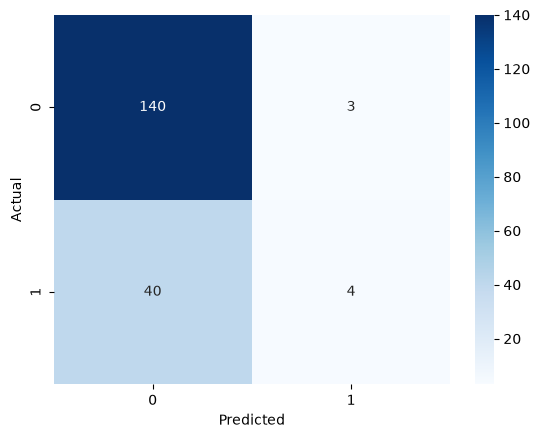

In [22]:
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()

## 15. Results and Insights
- The dataset has 748 donors, 4 numeric features and no missing values.
- Only about 24% of donors gave blood in the target month, so the classes are imbalanced.
- Logistic Regression reached about **77.0% accuracy**, with or without scaling.
- The model is very good at spotting non-donors (140 of 143 correct) but weak at finding donors (4 of 44).

## 16. Limitations
- **Accuracy is misleading** on imbalanced data: 77.0% is barely above the 76.5% baseline of always predicting "no".
- The model misses most real donors, which is the group a blood bank cares about most.
- Only one simple model was tried, with default settings and no cross-validation.
- The dataset is small (748 rows) and comes from one blood centre, so results may not generalise.

## 17. Next Steps
- Report **precision, recall, F1-score and ROC-AUC** instead of accuracy alone.
- Handle imbalance with `class_weight="balanced"`, or adjust the decision threshold to catch more donors.
- Compare other models (Random Forest, Gradient Boosting) and use cross-validation.
- Try feature engineering, for example donation rate = Frequency / Time.

## 18. Conclusion
A Logistic Regression model on donation history (recency, frequency, volume, time) predicts blood donation with about 77% accuracy, but the imbalanced data means it finds few actual donors. The project shows a full workflow (load, explore, prepare, model, evaluate) and why accuracy must be read with the confusion matrix. The next step is to improve donor recall with imbalance handling and other models.